# Análise Exploratória de Dados (EDA) — AVeriTeC

**RES IA ELD UNB — Turma 2 | Grupo 5 |**  
**Challenge 1 — FOMO**

## 1. Contextualização

O AVeriTeC é um conjunto de dados voltado à verificação de alegações, reunindo afirmações em inglês, rótulos de veracidade, metadados e evidências estruturadas utilizadas no processo de verificação.

Nesta etapa, será realizada a Análise Exploratória de Dados (EDA) das partições de treino (`train`) e desenvolvimento (`dev`) do AVeriTeC original.

A análise busca compreender as principais características do conjunto, avaliar a qualidade e a completude dos dados, identificar padrões e possíveis limitações e explorar aspectos relevantes das alegações e das evidências disponíveis.

Como o projeto FOMO envolve a análise de alegações e evidências para apoio à verificação de informações, compreender previamente a estrutura e as características do conjunto de dados é importante para orientar as próximas etapas de organização, preparação e utilização dos dados.

## 2. Objetivos da análise

A análise exploratória busca responder às seguintes questões:

- Qual é a dimensão do conjunto e quais variáveis estão disponíveis?
- Quais tipos de informações estão presentes nos registros?
- Existem valores ausentes ou problemas de completude nos campos analisados?
- Como os rótulos de veracidade estão distribuídos entre as partições de treino e desenvolvimento?
- Quais são as principais características de comprimento das alegações?
- Existem alegações com comprimento estatisticamente atípico e, em caso positivo, elas representam possíveis problemas nos dados?
- Quais palavras e expressões aparecem com maior frequência nas alegações?
- Quais tipos de entidades nomeadas são identificados nos textos e quais limitações aparecem nessa identificação automática?
- Como as perguntas e respostas utilizadas como evidência estão estruturadas?
- Quais tipos de resposta (`answer_type`) são mais frequentes?
- Quais características, limitações e desafios do conjunto devem ser considerados nas próximas etapas do projeto?

A análise será conduzida de forma exploratória, utilizando estatísticas descritivas, inspeção dos registros e visualizações para sustentar as principais descobertas.

## 3. Bibliotecas

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 4. Carregamento do AVeriTeC original

Nesta etapa, são carregadas as partições de treino (`train`) e desenvolvimento (`dev`) do AVeriTeC original.

Inicialmente, o conjunto será inspecionado de forma independente para verificar sua estrutura básica, quantidade de registros e formato dos dados.

As partições serão mantidas separadas para permitir a identificação de possíveis diferenças entre treino e desenvolvimento.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving dev (1).json to dev (1).json
Saving train (1).json to train (1).json


In [8]:
# Carregamento dos arquivos do AVeriTeC original

with open("/content/train (1).json", "r", encoding="utf-8") as f:
    train_original_raw = json.load(f)

with open("/content/dev (1).json", "r", encoding="utf-8") as f:
    dev_original_raw = json.load(f)

print("Tipo do train:", type(train_original_raw))
print("Tipo do dev:", type(dev_original_raw))

print("\nQuantidade de registros:")
print("Train:", len(train_original_raw))
print("Dev:", len(dev_original_raw))
print("Total:", len(train_original_raw) + len(dev_original_raw))

Tipo do train: <class 'list'>
Tipo do dev: <class 'list'>

Quantidade de registros:
Train: 3068
Dev: 500
Total: 3568


#### Resultado do carregamento

Os arquivos do AVeriTeC original utilizados nesta análise contêm **3.568 registros**, distribuídos em:

- **3.068 registros** no conjunto de treino;
- **500 registros** no conjunto de desenvolvimento (`dev`).

As duas partições foram carregadas como listas de registros em formato JSON.

As quantidades observadas são iguais às encontradas anteriormente nas respectivas partições do AVERITEC-BR. Essa equivalência inicial indica que as versões possuem o mesmo número de registros nos arquivos analisados, mas ainda não permite concluir que exista correspondência direta entre cada observação.

Essa correspondência será verificada posteriormente por meio da comparação da estrutura, dos metadados, dos rótulos e do conteúdo associado aos registros.

### 4.1 Estrutura dos registros

Após confirmar a quantidade de registros disponíveis, será analisada a estrutura interna de uma observação do conjunto de treino.

Essa inspeção permite identificar os campos disponíveis, verificar seus tipos e compreender como as informações relacionadas às alegações, rótulos e evidências estão organizadas no arquivo original. Essa etapa é especialmente importante antes da conversão para uma estrutura tabular, pois alguns campos podem apresentar estruturas aninhadas.

In [10]:
# Inspeção do primeiro registro do AVeriTeC original

print(json.dumps(
    train_original_raw[0],
    indent=2,
    ensure_ascii=False
))

{
  "claim": "Hunter Biden had no experience in Ukraine or in the energy sector when he joined the board of Burisma.",
  "required_reannotation": false,
  "label": "Supported",
  "justification": "No former experience stated.",
  "claim_date": "25-8-2020",
  "speaker": "Pam Bondi",
  "original_claim_url": null,
  "fact_checking_article": "https://web.archive.org/web/20210111003633/https://www.politifact.com/article/2020/aug/26/fact-checking-second-night-2020-rnc/",
  "reporting_source": "Speech at The Republican National Convention",
  "location_ISO_code": "US",
  "claim_types": [
    "Position Statement"
  ],
  "fact_checking_strategies": [
    "Written Evidence"
  ],
  "questions": [
    {
      "question": "Did Hunter Biden have any experience in the energy sector at the time he joined the board of the  Burisma energy company in 2014",
      "answers": [
        {
          "answer": "No",
          "answer_type": "Boolean",
          "source_url": "https://en.wikipedia.org/wiki/Hun

#### Observações sobre a estrutura

A inspeção do primeiro registro mostra que o AVeriTeC original apresenta uma estrutura rica em informações, combinando dados da alegação, metadados e evidências utilizadas no processo de verificação.

Entre os campos principais estão:

- `claim`: texto da alegação;
- `label`: classificação atribuída à alegação;
- `justification`: justificativa associada à classificação;
- `claim_date`: data relacionada à alegação;
- `speaker`: pessoa ou entidade associada à declaração;
- `reporting_source`: origem ou contexto em que a alegação foi publicada;
- `location_ISO_code`: código de localização;
- `claim_types`: tipo ou tipos associados à alegação;
- `fact_checking_strategies`: estratégias utilizadas na verificação;
- `required_reannotation`: indicação de necessidade de reanotação.

Também estão presentes campos relacionados às fontes, como `original_claim_url`, `fact_checking_article` e `cached_original_claim_url`.

A estrutura de evidências é armazenada de forma aninhada no campo `questions`. Cada registro pode conter uma ou mais perguntas utilizadas para investigar a alegação e, para cada pergunta, uma lista de respostas (`answers`).

As respostas podem conter informações como o conteúdo da evidência (`answer`), o tipo de resposta (`answer_type`), a fonte (`source_url`), o meio da fonte (`source_medium`) e campos complementares específicos do tipo de resposta, como `boolean_explanation`.

No registro inspecionado, por exemplo, a alegação possui duas perguntas de verificação, ambas acompanhadas por respostas do tipo `Boolean`.

A presença dessas estruturas aninhadas confirma que parte das informações não pode ser representada diretamente como uma única variável tabular sem algum tratamento adicional. Por esse motivo, as alegações e seus metadados poderão ser analisados em uma estrutura principal, enquanto perguntas e respostas poderão ser exploradas separadamente quando necessário.

### 4.2 Conversão para DataFrame e visão geral das variáveis

Após a inspeção da estrutura dos registros, os dados das partições de treino e desenvolvimento serão convertidos para DataFrames.

Essa representação facilita a análise das variáveis presentes no nível principal de cada registro, permitindo verificar dimensões, nomes das colunas e tipos de dados.

Os campos aninhados, como `questions`, serão mantidos nesta etapa e poderão ser explorados separadamente quando necessário.

In [11]:
# Conversão para DataFrame

train_original = pd.DataFrame(train_original_raw)
dev_original = pd.DataFrame(dev_original_raw)

print("Dimensão do Train:", train_original.shape)
print("Dimensão do Dev:", dev_original.shape)

print("\nColunas disponíveis:")
print(train_original.columns.tolist())

print("\nTipos de dados:")
print(train_original.dtypes)

Dimensão do Train: (3068, 14)
Dimensão do Dev: (500, 14)

Colunas disponíveis:
['claim', 'required_reannotation', 'label', 'justification', 'claim_date', 'speaker', 'original_claim_url', 'fact_checking_article', 'reporting_source', 'location_ISO_code', 'claim_types', 'fact_checking_strategies', 'questions', 'cached_original_claim_url']

Tipos de dados:
claim                        object
required_reannotation          bool
label                        object
justification                object
claim_date                   object
speaker                      object
original_claim_url           object
fact_checking_article        object
reporting_source             object
location_ISO_code            object
claim_types                  object
fact_checking_strategies     object
questions                    object
cached_original_claim_url    object
dtype: object


#### Observações sobre a estrutura tabular

Após a conversão, o conjunto de treino apresenta **3.068 registros e 14 variáveis**, enquanto o conjunto de desenvolvimento apresenta **500 registros e as mesmas 14 variáveis**.

As colunas disponíveis correspondem aos campos identificados anteriormente na estrutura JSON, incluindo informações sobre a alegação, classificação, metadados, fontes e evidências.

A variável `required_reannotation` é representada como booleana (`bool`). As demais variáveis aparecem como `object`, o que inclui tanto campos textuais quanto estruturas mais complexas armazenadas em listas ou objetos, como `claim_types`, `fact_checking_strategies` e `questions`.

Essa estrutura é equivalente, em quantidade de colunas e organização geral, à observada anteriormente no AVERITEC-BR. A equivalência estrutural, entretanto, ainda não demonstra que os conteúdos e metadados tenham sido integralmente preservados entre as versões, o que será investigado posteriormente na análise comparativa.

### 4.3 Qualidade e completude dos dados

Após a análise da estrutura do AVeriTeC, será avaliada a qualidade e a completude das informações presentes nas partições de treino e desenvolvimento.

Inicialmente, serão identificados os valores ausentes em cada variável, considerando tanto valores nulos quanto campos vazios quando aplicável. A análise da ausência de dados é importante para distinguir problemas que afetam informações essenciais, como alegações e rótulos, de ausências associadas a metadados opcionais.

Os valores ausentes serão analisados antes de qualquer decisão de remoção ou preenchimento, uma vez que diferentes campos podem apresentar funções e níveis de importância distintos no conjunto de dados.

In [12]:
# Função para identificar valores ausentes,
# considerando valores nulos e strings vazias

def analisar_ausentes(df):
    resultado = []

    for coluna in df.columns:
        nulos = df[coluna].isna().sum()

        # Conta strings vazias apenas em valores textuais
        vazios = df[coluna].apply(
            lambda x: isinstance(x, str) and x.strip() == ""
        ).sum()

        total_ausentes = nulos + vazios
        percentual = (total_ausentes / len(df)) * 100

        resultado.append({
            "Variável": coluna,
            "Ausentes": total_ausentes,
            "Percentual (%)": round(percentual, 2)
        })

    return pd.DataFrame(resultado)


ausentes_train_original = analisar_ausentes(train_original)
ausentes_dev_original = analisar_ausentes(dev_original)

print("VALORES AUSENTES — TRAIN")
display(ausentes_train_original)

print("\nVALORES AUSENTES — DEV")
display(ausentes_dev_original)

VALORES AUSENTES — TRAIN


,Variável,Ausentes,Percentual (%)
0,claim,1,0.03
1,required_reannotation,0,0.00
2,label,0,0.00
3,justification,0,0.00
4,claim_date,105,3.42
5,speaker,695,22.65
6,original_claim_url,1611,52.51
7,fact_checking_article,0,0.00
8,reporting_source,615,20.05
9,location_ISO_code,336,10.95



VALORES AUSENTES — DEV


,Variável,Ausentes,Percentual (%)
0,claim,0,0.0
1,required_reannotation,0,0.0
2,label,0,0.0
3,justification,0,0.0
4,claim_date,0,0.0
5,speaker,118,23.6
6,original_claim_url,238,47.6
7,fact_checking_article,0,0.0
8,reporting_source,90,18.0
9,location_ISO_code,50,10.0


#### Observações sobre valores ausentes

A análise mostra que os campos centrais do AVeriTeC apresentam alto nível de completude.

No conjunto de treino, `label`, `justification`, `required_reannotation`, `fact_checking_article`, `claim_types`, `fact_checking_strategies` e `questions` não apresentam valores ausentes. O campo `claim`, essencial para a análise textual, possui apenas **1 registro ausente (0,03%)**.

As maiores proporções de ausência estão concentradas principalmente em campos relacionados a metadados e URLs. No treino, destacam-se:

- `cached_original_claim_url`: **62,68%**;
- `original_claim_url`: **52,51%**;
- `speaker`: **22,65%**;
- `reporting_source`: **20,05%**;
- `location_ISO_code`: **10,95%**;
- `claim_date`: **3,42%**.

No conjunto de desenvolvimento, os campos essenciais também permanecem completos. As maiores proporções de ausência são observadas em `cached_original_claim_url` (**48,40%**), `original_claim_url` (**47,60%**), `speaker` (**23,60%**), `reporting_source` (**18,00%**) e `location_ISO_code` (**10,00%**).

Dessa forma, a ausência de dados está concentrada principalmente em informações complementares, enquanto os campos diretamente relacionados à classificação e à estrutura de evidências apresentam elevada completude.

Neste momento, não será realizada imputação ou remoção automática desses registros. A relevância das ausências será considerada de acordo com o tipo de análise realizada posteriormente.

In [13]:
# Inspeção do registro sem texto de claim

registro_claim_ausente = train_original[
    train_original["claim"].isna() |
    train_original["claim"].apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    )
]

display(registro_claim_ausente)

,claim,required_reannotation,label,justification,claim_date,speaker,original_claim_url,fact_checking_article,reporting_source,location_ISO_code,claim_types,fact_checking_strategies,questions,cached_original_claim_url
1948,,False,Supported,The claim is correct.,8-7-2019,None,None,https://web.archive.org/web/20210720180947/https://dubawa.org/inec-chairmans-claims-whats-true-and-whats-not/,None,NG,[Position Statement],[Written Evidence],"[{'question': 'Do some countries campaign until the day of election?', 'answers': [{'answer': 'Yes', 'answer_type': 'Boolean', 'source_url': 'https://web.archive.org/web/20210720180947/https://www...",NaN


#### Inspeção do registro sem `claim`

Foi identificado apenas um registro do conjunto de treino sem texto no campo `claim`, correspondente ao índice **1948**.

Apesar da ausência da alegação, o registro mantém outras informações relevantes, incluindo o rótulo `Supported`, justificativa, data, localização, tipo de alegação, estratégia de verificação e estrutura de perguntas e respostas.

Dessa forma, o registro não será removido integralmente nesta etapa. Ele será desconsiderado apenas nas análises que dependem diretamente do conteúdo textual de `claim`, permanecendo disponível para análises de outras variáveis e da estrutura de evidências.

### 4.4 Verificação de duplicatas

Além dos valores ausentes, será verificada a presença de registros duplicados nas partições de treino e desenvolvimento.

A análise considera dois níveis:

- duplicações completas, em que todas as informações do registro são repetidas;
- alegações (`claim`) textualmente repetidas dentro de cada partição.

Também será verificada a existência de alegações idênticas presentes simultaneamente nos conjuntos de treino e desenvolvimento, pois esse tipo de sobreposição pode ser relevante em futuras etapas de avaliação.

In [37]:
# Duplicatas completas
train_serializado = pd.Series([
    json.dumps(registro, sort_keys=True, ensure_ascii=False)
    for registro in train_original_raw
])

dev_serializado = pd.Series([
    json.dumps(registro, sort_keys=True, ensure_ascii=False)
    for registro in dev_original_raw
])

duplicatas_completas_train = train_serializado.duplicated().sum()
duplicatas_completas_dev = dev_serializado.duplicated().sum()

print("DUPLICATAS COMPLETAS")
print(
    f"Train: {duplicatas_completas_train} "
    f"({duplicatas_completas_train / len(train_serializado) * 100:.2f}%)"
)
print(
    f"Dev: {duplicatas_completas_dev} "
    f"({duplicatas_completas_dev / len(dev_serializado) * 100:.2f}%)"
)


# Claims válidas
claims_train = (
    train_original["claim"]
    .dropna()
    .astype(str)
    .str.strip()
)

claims_train = claims_train[claims_train != ""]

claims_dev = (
    dev_original["claim"]
    .dropna()
    .astype(str)
    .str.strip()
)

claims_dev = claims_dev[claims_dev != ""]


# Claims repetidas dentro de cada partição
duplicadas_train = claims_train.duplicated(keep=False)
duplicadas_dev = claims_dev.duplicated(keep=False)

n_registros_repetidos_train = duplicadas_train.sum()
n_registros_repetidos_dev = duplicadas_dev.sum()

n_claims_distintas_train = claims_train[duplicadas_train].nunique()
n_claims_distintas_dev = claims_dev[duplicadas_dev].nunique()

print("\nCLAIMS ENVOLVIDAS EM REPETIÇÕES")
print(
    f"Train: {n_registros_repetidos_train} "
    f"({n_registros_repetidos_train / len(claims_train) * 100:.2f}%)"
)
print(
    f"Dev: {n_registros_repetidos_dev} "
    f"({n_registros_repetidos_dev / len(claims_dev) * 100:.2f}%)"
)

print("\nCLAIMS DISTINTAS QUE SE REPETEM")
print("Train:", n_claims_distintas_train)
print("Dev:", n_claims_distintas_dev)


# Sobreposição entre Train e Dev
sobreposicao = set(claims_train) & set(claims_dev)

print("\nCLAIMS IDÊNTICAS PRESENTES EM TRAIN E DEV")
print(
    f"{len(sobreposicao)} "
    f"({len(sobreposicao) / len(set(claims_dev)) * 100:.2f}% das claims distintas do Dev)"
)

DUPLICATAS COMPLETAS
Train: 0 (0.00%)
Dev: 0 (0.00%)

CLAIMS ENVOLVIDAS EM REPETIÇÕES
Train: 109 (3.55%)
Dev: 15 (3.00%)

CLAIMS DISTINTAS QUE SE REPETEM
Train: 40
Dev: 6

CLAIMS IDÊNTICAS PRESENTES EM TRAIN E DEV
4 (0.81% das claims distintas do Dev)


#### Resultado da análise de duplicatas

Não foram identificados registros completamente duplicados nas partições de treino ou desenvolvimento do AVeriTeC original.

Entretanto, foram observadas alegações textualmente repetidas dentro das próprias partições. No conjunto de treino, **109 registros (3,55%)** estão envolvidos em repetições, correspondendo a **40 alegações distintas que aparecem mais de uma vez**. No conjunto de desenvolvimento, **15 registros (3,00%)** estão envolvidos em repetições, correspondendo a **6 alegações distintas repetidas**.

Também foram identificadas **4 alegações textualmente idênticas presentes simultaneamente nos conjuntos de treino e desenvolvimento**, correspondendo a **0,81% das alegações distintas do conjunto de desenvolvimento**.

Esses resultados mostram que a repetição ocorre no nível textual das alegações, mesmo sem duplicação completa dos registros. A existência de alegações repetidas e de uma pequena sobreposição entre treino e desenvolvimento deve ser considerada em futuras etapas de preparação e avaliação dos dados, especialmente em abordagens baseadas no texto da alegação.

#### Considerações sobre a continuidade da análise

As verificações iniciais mostram que o AVeriTeC original apresenta a mesma quantidade de registros, as mesmas variáveis e um padrão de valores ausentes semelhante ao observado na versão AVERITEC-BR analisada anteriormente.

A análise de duplicatas também mostrou que, embora não existam registros completamente duplicados, há alegações textualmente repetidas dentro das partições e uma pequena sobreposição entre treino e desenvolvimento, com **4 alegações idênticas presentes em ambos os conjuntos**.

Como o AVERITEC-BR foi construído a partir da tradução do AVeriTeC, diversas características estruturais dos dois conjuntos são naturalmente compartilhadas. Por esse motivo, as próximas etapas desta análise priorizarão características relevantes para a compreensão do conjunto original, evitando a repetição extensa de explorações estruturais já realizadas na versão traduzida.

Será dada maior atenção à distribuição dos rótulos, às características do conteúdo textual em inglês e aos padrões linguísticos observados no conjunto, mantendo verificações adicionais de qualidade e evidências quando necessárias.

## 5. Distribuição dos rótulos

A distribuição das classes é um aspecto importante para compreender o equilíbrio do conjunto de dados e identificar possíveis diferenças de representação entre os rótulos.

Nesta etapa, serão analisadas as frequências absolutas e relativas dos rótulos nas partições de treino e desenvolvimento do AVeriTeC.

A comparação entre as duas partições também permite verificar se a distribuição das classes permanece semelhante entre os conjuntos.

In [14]:
# Distribuição dos rótulos no Train

labels_train = (
    train_original["label"]
    .value_counts()
    .to_frame("Quantidade")
)

labels_train["Percentual (%)"] = (
    train_original["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("DISTRIBUIÇÃO DOS RÓTULOS — TRAIN")
display(labels_train)


# Distribuição dos rótulos no Dev

labels_dev = (
    dev_original["label"]
    .value_counts()
    .to_frame("Quantidade")
)

labels_dev["Percentual (%)"] = (
    dev_original["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDISTRIBUIÇÃO DOS RÓTULOS — DEV")
display(labels_dev)

DISTRIBUIÇÃO DOS RÓTULOS — TRAIN


,Quantidade,Percentual (%)
label,,
Refuted,1742,56.78
Supported,849,27.67
Not Enough Evidence,282,9.19
Conflicting Evidence/Cherrypicking,195,6.36



DISTRIBUIÇÃO DOS RÓTULOS — DEV


,Quantidade,Percentual (%)
label,,
Refuted,305,61.0
Supported,122,24.4
Conflicting Evidence/Cherrypicking,38,7.6
Not Enough Evidence,35,7.0


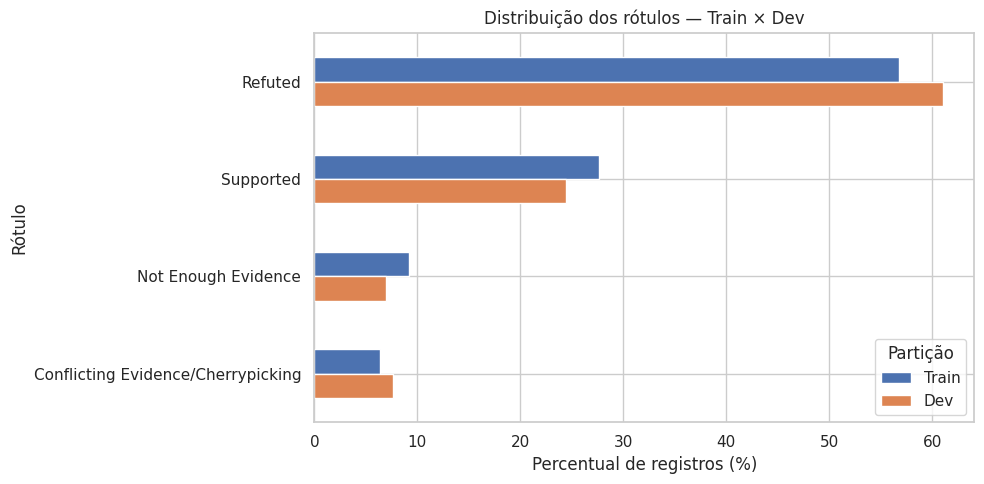

In [17]:
# Comparação da distribuição percentual dos rótulos entre Train e Dev

dist_train = (
    train_original["label"]
    .value_counts(normalize=True)
    .mul(100)
)

dist_dev = (
    dev_original["label"]
    .value_counts(normalize=True)
    .mul(100)
)

ordem_labels = dist_train.index.tolist()

comparacao_labels = pd.DataFrame({
    "Train": dist_train,
    "Dev": dist_dev
}).reindex(ordem_labels)

ax = comparacao_labels.plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Distribuição dos rótulos — Train × Dev")
plt.xlabel("Percentual de registros (%)")
plt.ylabel("Rótulo")
plt.legend(title="Partição")

# Maior percentual no topo
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### 5.1 Interpretação da distribuição dos rótulos

A distribuição dos rótulos mostra que o AVeriTeC apresenta **desbalanceamento entre as classes**.

No conjunto de treino, a classe `Refuted` é predominante, representando **56,78%** dos registros, seguida por `Supported`, com **27,67%**. As classes menos frequentes são `Not Enough Evidence`, com **9,19%**, e `Conflicting Evidence/Cherrypicking`, com **6,36%**.

No conjunto de desenvolvimento, observa-se comportamento semelhante. A classe `Refuted` corresponde a **61,00%** dos registros e `Supported` a **24,40%**, enquanto `Conflicting Evidence/Cherrypicking` representa **7,60%** e `Not Enough Evidence` **7,00%**.

O gráfico evidencia que as duas partições mantêm uma composição geral semelhante, com predominância de alegações classificadas como `Refuted` e menor representação das classes relacionadas à insuficiência ou ao conflito de evidências.

Esse desbalanceamento é uma característica relevante para etapas posteriores do projeto, pois métricas globais de desempenho podem ser influenciadas pela maior representação das classes predominantes. Assim, avaliações futuras deverão considerar também o desempenho por classe, especialmente nas categorias menos frequentes.

## 6. Características textuais das alegações

Após a análise da distribuição dos rótulos, serão exploradas as características textuais das alegações presentes no AVeriTeC.

Como o campo `claim` contém o conteúdo principal das afirmações verificadas, compreender seu tamanho e sua variabilidade ajuda a caracterizar o tipo de texto presente no conjunto e a identificar observações muito curtas ou muito extensas.

Inicialmente, serão analisados o número de caracteres e o número de palavras das alegações nas partições de treino e desenvolvimento. O único registro do conjunto de treino sem conteúdo em `claim`, identificado anteriormente, será desconsiderado apenas nesta análise textual.

In [19]:
# Seleção apenas de registros com claim textual válida

train_texto = train_original[
    train_original["claim"].notna() &
    train_original["claim"].astype(str).str.strip().ne("")
].copy()

dev_texto = dev_original[
    dev_original["claim"].notna() &
    dev_original["claim"].astype(str).str.strip().ne("")
].copy()

# Comprimento em caracteres e palavras

train_texto["num_caracteres"] = train_texto["claim"].str.len()
train_texto["num_palavras"] = train_texto["claim"].str.split().str.len()

dev_texto["num_caracteres"] = dev_texto["claim"].str.len()
dev_texto["num_palavras"] = dev_texto["claim"].str.split().str.len()

# Estatísticas descritivas

print("Registros utilizados na análise textual:")
print("Train:", len(train_texto))
print("Dev:", len(dev_texto))

print("\nCOMPRIMENTO DAS CLAIMS — TRAIN")
display(
    train_texto[["num_caracteres", "num_palavras"]]
    .describe()
    .round(2)
)

print("\nCOMPRIMENTO DAS CLAIMS — DEV")
display(
    dev_texto[["num_caracteres", "num_palavras"]]
    .describe()
    .round(2)
)

Registros utilizados na análise textual:
Train: 3067
Dev: 500

COMPRIMENTO DAS CLAIMS — TRAIN


,num_caracteres,num_palavras
count,3067.00,3067.00
mean,103.40,17.04
std,51.93,8.66
min,18.00,3.00
25%,68.50,11.00
50%,93.00,15.00
75%,125.00,21.00
max,392.00,73.00



COMPRIMENTO DAS CLAIMS — DEV


,num_caracteres,num_palavras
count,500.00,500.00
mean,105.73,17.39
std,49.35,8.10
min,19.00,3.00
25%,70.00,12.00
50%,96.00,16.00
75%,134.00,22.00
max,390.00,66.00


### 6.1 Interpretação do comprimento das alegações

Após a exclusão do único registro sem conteúdo textual em `claim`, foram analisadas **3.067 alegações no conjunto de treino** e **500 no conjunto de desenvolvimento**.

No conjunto de treino, as alegações apresentam em média **103,40 caracteres** e **17,04 palavras**, com mediana de **93 caracteres** e **15 palavras**. Metade das observações possui entre **11 e 21 palavras**, enquanto o maior texto contém **73 palavras**.

No conjunto de desenvolvimento, o comportamento é semelhante, com média de **105,73 caracteres** e **17,39 palavras** e medianas de **96 caracteres** e **16 palavras**. Metade das alegações possui entre **12 e 22 palavras**, e o maior registro contém **66 palavras**.

De forma geral, as duas partições apresentam características textuais semelhantes quanto ao comprimento das alegações. A proximidade entre médias, medianas e intervalos interquartis indica que não há uma diferença expressiva de extensão textual entre os conjuntos de treino e desenvolvimento.

Entretanto, os valores máximos são consideravelmente superiores aos valores típicos observados no conjunto, indicando a presença de algumas alegações mais extensas. Esses registros serão examinados antes de serem considerados possíveis anomalias.

In [20]:
# Identificação de possíveis outliers de comprimento no Train pelo método IQR

q1 = train_texto["num_palavras"].quantile(0.25)
q3 = train_texto["num_palavras"].quantile(0.75)

iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_comprimento = train_texto[
    train_texto["num_palavras"] > limite_superior
].copy()

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)

print("\nClaims acima do limite superior:", len(outliers_comprimento))
print(
    "Percentual:",
    round(len(outliers_comprimento) / len(train_texto) * 100, 2),
    "%"
)

Q1: 11.0
Q3: 21.0
IQR: 10.0
Limite inferior: -4.0
Limite superior: 36.0

Claims acima do limite superior: 96
Percentual: 3.13 %


### 6.2 Identificação de alegações com comprimento atípico

Para identificar alegações com comprimento elevado em relação ao restante do conjunto, foi aplicado o método do intervalo interquartil (IQR) sobre o número de palavras das `claims` do conjunto de treino.

O primeiro quartil (Q1) corresponde a **11 palavras** e o terceiro quartil (Q3) a **21 palavras**, resultando em um IQR de **10 palavras**. Com a aplicação do critério de 1,5 × IQR, o limite superior calculado foi de **36 palavras**.

Foram identificadas **96 alegações acima desse limite**, correspondendo a **3,13%** das alegações válidas do conjunto de treino.

Esses registros não serão considerados automaticamente como erros ou removidos. O método IQR identifica observações estatisticamente distantes da distribuição central, mas alegações mais extensas podem representar conteúdo legítimo do conjunto. Por isso, os registros de maior comprimento serão inspecionados antes de qualquer conclusão sobre possíveis anomalias.

In [21]:
# Inspeção das 10 claims mais extensas do conjunto de treino

claims_mais_longas = (
    train_texto[
        ["claim", "label", "num_palavras", "num_caracteres"]
    ]
    .sort_values("num_palavras", ascending=False)
    .head(10)
)

display(claims_mais_longas)

,claim,label,num_palavras,num_caracteres
2509,"For many, many decades veterans have been trying to get VA Choice. You couldn’t get it. ... Now these great veterans, if there’s a big wait, they go outside, they go to a local doctor. We pay the ...",Refuted,73,374
1047,"F. Scott Fitzgerald wrote a letter in the 1920 Spanish Influenza pandemic, in which he wrote to someone named “Rosemary” in which he wrote: “Even the bars, as I told Hemingway, but to that he punc...",Refuted,72,385
2971,"or the first time ever, an African passport is among the top five most powerful in the world. Revealing this on Monday on its website, the Henley Passport Index released its ranking for the year 2...",Refuted,66,359
2578,"You have chain migration. Where a bad person comes in, brings 22 or 23 or 35 of his family members, because he has his mother, his grandmother, sister, cousin, uncle. They are all in. You know wha...",Refuted,66,357
2296,"William Shakespeare wrote “I always feel happy, you know why? Because I don’t expect anything from anyone. Expectations always hurt. Life is short, so love your life, be happy. And keep smiling. J...",Refuted,65,390
112,"COVID-19 medical face masks are designed to be worn differently depending on the health of the wearer, masks should be worn colored side out if you are sick and do not want to spread germs around ...",Not Enough Evidence,64,330
1776,"Donald Trump threatened economic sanctions over recent xenophobic violence in South Africa with a posted tweet stating “This barbaric attacks by South African is very disappointing, its time we pu...",Refuted,63,387
2876,"Kansas City Chiefs CEO Clark Hunt said ""You will stand, with your hand over your heart and with respect, when our country’s national anthem is being played or you will no longer be a Kansas City C...",Refuted,62,343
2211,"Nelson Mandela said\n'When a woman rejects a man of vision, and accept [sic] a man with television, she will end up watching the man of vision on her own husband's television,” it reads.\n\n “Don'...",Refuted,62,333
607,"Thousands of arrests have been made in the US for child trafficking, human trafficking and sex abuse but the media is not reporting it. Nurses are coming forward speaking publicly about the fact t...",Not Enough Evidence,60,378


#### Inspeção das alegações mais extensas

A inspeção das dez alegações com maior número de palavras mostra que os registros identificados pelo critério do IQR correspondem, em sua maioria, a **citações extensas, declarações compostas ou alegações que incorporam maior quantidade de contexto**.

Os textos permanecem semanticamente coerentes e não apresentam, nessa inspeção, sinais evidentes de concatenação indevida de registros ou outros erros estruturais.

Portanto, o comprimento elevado não será tratado como erro nem utilizado como critério para remoção. As **96 alegações acima do limite de 36 palavras** serão mantidas no conjunto, considerando que representam aproximadamente **3,13%** das alegações válidas e podem refletir uma característica legítima dos dados.

Esse resultado também demonstra a importância de inspecionar os valores identificados estatisticamente como atípicos antes de classificá-los como anomalias.

### 6.3 Padrões lexicais das alegações

Além do comprimento das alegações, a análise das palavras utilizadas no conjunto permite identificar temas, entidades e assuntos recorrentes no AVeriTeC original.

Para essa exploração, será realizada uma preparação textual simples, com conversão para letras minúsculas, remoção de URLs, caracteres não alfabéticos e palavras muito frequentes da língua inglesa (*stopwords*).

A palavra `not` será preservada durante a remoção de *stopwords*, pois expressões de negação podem carregar informação relevante no contexto de alegações verificadas.

Nesta etapa não serão aplicadas técnicas de *stemming* ou lematização, de forma a preservar as palavras em sua forma original para a análise exploratória.

In [23]:
import nltk
from nltk.corpus import stopwords

# Download da lista de stopwords do NLTK
nltk.download("stopwords", quiet=True)

# Stopwords em inglês
stopwords_en = set(stopwords.words("english"))

# Preservação de termos de negação relevantes
stopwords_en.discard("not")
stopwords_en.discard("no")
stopwords_en.discard("nor")


def limpar_texto_ingles(texto):
    texto = texto.lower()

    # Remove URLs
    texto = re.sub(r"http\S+|www\S+", " ", texto)

    # Mantém apenas letras e espaços
    texto = re.sub(r"[^a-z\s]", " ", texto)

    # Remove espaços extras
    palavras = texto.split()

    # Remove stopwords
    palavras = [
        palavra
        for palavra in palavras
        if palavra not in stopwords_en
    ]

    return palavras


# Aplicação da limpeza às claims válidas do Train

tokens_claims = train_texto["claim"].apply(limpar_texto_ingles)

# Quantidade total de tokens após a preparação
total_tokens = sum(len(tokens) for tokens in tokens_claims)

print("Claims analisadas:", len(tokens_claims))
print("Total de tokens após a preparação:", total_tokens)

print("\nExemplo — claim original:")
print(train_texto.iloc[0]["claim"])

print("\nExemplo — após a preparação:")
print(tokens_claims.iloc[0])

Claims analisadas: 3067
Total de tokens após a preparação: 31656

Exemplo — claim original:
Hunter Biden had no experience in Ukraine or in the energy sector when he joined the board of Burisma.

Exemplo — após a preparação:
['hunter', 'biden', 'no', 'experience', 'ukraine', 'energy', 'sector', 'joined', 'board', 'burisma']


#### Preparação dos textos

Após a preparação textual, foram mantidas **3.067 alegações válidas**, totalizando **31.656 tokens** para a análise lexical.

A inspeção de um exemplo mostra que a etapa de limpeza removeu palavras funcionais muito frequentes da língua inglesa e manteve termos semanticamente relevantes para o conteúdo da alegação.

Termos de negação, como `no`, foram preservados intencionalmente, pois podem modificar diretamente o sentido de uma afirmação e, portanto, são relevantes no contexto de verificação de alegações.

In [24]:
# Frequência das palavras após a preparação textual

todas_palavras = [
    palavra
    for tokens in tokens_claims
    for palavra in tokens
]

frequencia_palavras = Counter(todas_palavras)

top_palavras = pd.DataFrame(
    frequencia_palavras.most_common(30),
    columns=["Palavra", "Frequência"]
)

display(top_palavras)

,Palavra,Frequência
0,covid,287
1,president,256
2,trump,250
3,people,245
4,us,241
5,not,205
6,coronavirus,204
7,million,193
8,said,175
9,years,164


#### Palavras mais frequentes

As palavras mais frequentes indicam a presença de temas recorrentes relacionados principalmente a **política, saúde pública, países e regiões geográficas**.

Entre os termos de maior frequência aparecem `covid`, `coronavirus`, `pandemic` e `health`, associados ao contexto de saúde; `president`, `trump`, `donald` e `biden`, relacionados ao cenário político; e termos geográficos como `kenya`, `nigeria`, `africa`, `india` e `china`.

Também aparecem termos quantitativos, como `million` e `billion`, indicando a presença recorrente de alegações envolvendo valores ou quantidades.

Os termos de negação `not` e `no`, preservados durante a preparação textual, também apresentam frequência relevante.

Foi identificado ainda o token isolado `u`, provavelmente produzido pela remoção de pontuação em abreviações presentes no texto. Por não representar isoladamente um termo semanticamente informativo, ele será desconsiderado apenas na visualização das palavras mais frequentes, sem alteração dos textos originais.

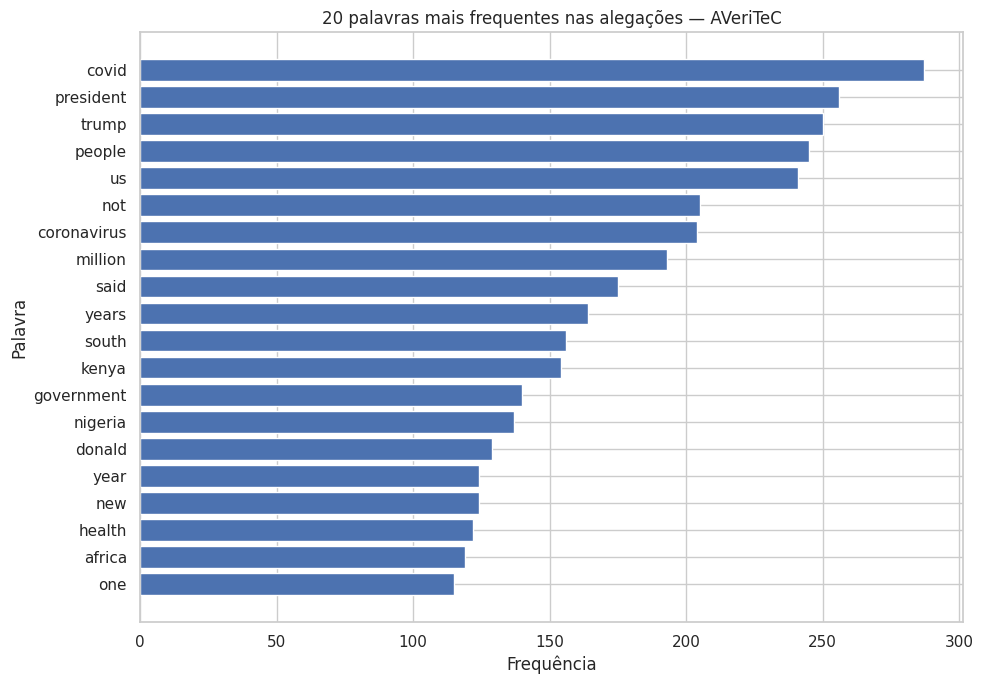

In [25]:
# Preparação dos dados para visualização
# O token isolado "u" é excluído apenas do gráfico

palavras_grafico = [
    (palavra, frequencia)
    for palavra, frequencia in frequencia_palavras.most_common()
    if palavra != "u"
][:20]

df_palavras_grafico = pd.DataFrame(
    palavras_grafico,
    columns=["Palavra", "Frequência"]
)

# Ordem crescente para o gráfico horizontal
df_palavras_grafico = df_palavras_grafico.sort_values(
    "Frequência",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    df_palavras_grafico["Palavra"],
    df_palavras_grafico["Frequência"]
)

plt.title("20 palavras mais frequentes nas alegações — AVeriTeC")
plt.xlabel("Frequência")
plt.ylabel("Palavra")
plt.tight_layout()
plt.show()

O gráfico reforça a concentração de termos relacionados a saúde pública e política entre as alegações analisadas. Entretanto, a interpretação de palavras isoladas apresenta algumas limitações. Termos como `us`, por exemplo, podem possuir mais de um significado dependendo do contexto, enquanto palavras como `south`, `africa`, `donald`, `united` e `states` podem fazer parte de expressões compostas. Por esse motivo, a análise de bigramas será utilizada como complemento para identificar combinações recorrentes de palavras e fornecer maior contexto aos padrões lexicais observados.

### 6.4 Bigramas mais frequentes

A análise de palavras isoladas permite identificar termos recorrentes, mas não mostra necessariamente o contexto em que eles aparecem.

Para complementar essa exploração, serão analisados os **bigramas**, isto é, pares de palavras consecutivas presentes nas alegações após a preparação textual.

Essa análise permite identificar expressões recorrentes, nomes compostos, localidades e outros padrões que podem ser fragmentados quando cada palavra é analisada individualmente.

In [26]:
# Construção dos bigramas a partir dos tokens de cada claim

bigramas = []

for tokens in tokens_claims:
    bigramas.extend(
        zip(tokens, tokens[1:])
    )

# Frequência dos bigramas
frequencia_bigramas = Counter(bigramas)

# 30 bigramas mais frequentes
top_bigramas = pd.DataFrame(
    [
        (" ".join(bigrama), frequencia)
        for bigrama, frequencia
        in frequencia_bigramas.most_common(30)
    ],
    columns=["Bigrama", "Frequência"]
)

display(top_bigramas)

,Bigrama,Frequência
0,donald trump,126
1,south africa,86
2,united states,75
3,president donald,48
4,joe biden,47
5,five years,40
6,new york,35
7,covid pandemic,31
8,prime minister,31
9,us president,31


#### Interpretação dos bigramas

A análise dos bigramas fornece maior contexto aos padrões identificados anteriormente nas palavras isoladas.

Entre as combinações mais frequentes aparecem nomes de figuras políticas, como `donald trump`, `joe biden` e `barack obama`, além de expressões geográficas como `south africa`, `united states` e `new york`.

Também são observadas combinações relacionadas à saúde e à pandemia de COVID-19, como `covid pandemic`, `novel coronavirus`, `coronavirus pandemic`, `world health` e `health care`.

Outras expressões, como `prime minister`, `vice president`, `social security` e `world bank`, reforçam a presença de temas relacionados a política, instituições e questões socioeconômicas.

Os bigramas também ajudam a contextualizar termos que, isoladamente, eram menos informativos. Por exemplo, `south` aparece frequentemente associado a `africa`, enquanto `united` e `states` formam a expressão `united states`.

De forma geral, os resultados reforçam a presença de conteúdos relacionados a **política, saúde pública, localidades e instituições** entre as alegações do AVeriTeC.

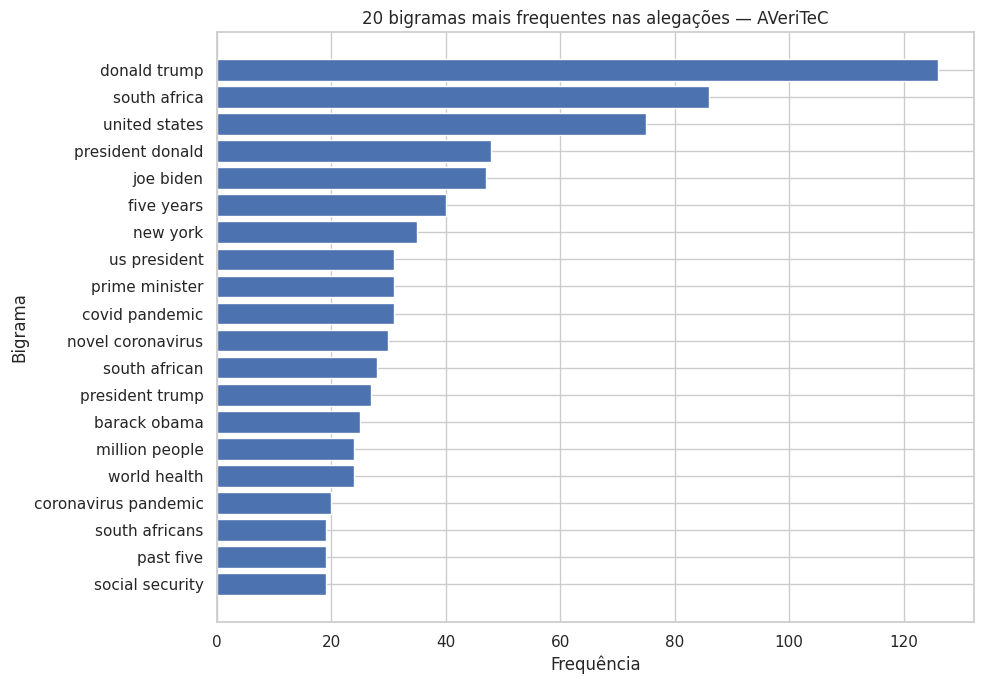

In [27]:
# Seleção dos 20 bigramas mais frequentes

bigramas_grafico = top_bigramas.head(20).copy()

# Ordem crescente para visualização horizontal
bigramas_grafico = bigramas_grafico.sort_values(
    "Frequência",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    bigramas_grafico["Bigrama"],
    bigramas_grafico["Frequência"]
)

plt.title("20 bigramas mais frequentes nas alegações — AVeriTeC")
plt.xlabel("Frequência")
plt.ylabel("Bigrama")

plt.tight_layout()
plt.show()

## 7. Entidades nomeadas nas alegações

Para complementar a análise textual, será realizada uma exploração das entidades nomeadas presentes nas alegações do AVeriTeC.

O reconhecimento de entidades nomeadas (*Named Entity Recognition* — NER) permite identificar automaticamente referências a pessoas, organizações, localidades e outras categorias presentes nos textos.

Essa análise pode ajudar a caracterizar os principais tipos de entidades mencionadas nas alegações. Entretanto, os resultados serão utilizados apenas de forma exploratória, uma vez que modelos automáticos de NER podem apresentar erros de classificação, fragmentação ou omissão de entidades.

In [28]:
# Instalação do modelo de língua inglesa do spaCy

!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [29]:
import spacy

# Carregamento do modelo em inglês
nlp = spacy.load("en_core_web_sm")

print("Modelo carregado com sucesso!")

Modelo carregado com sucesso!


In [30]:
# Extração de entidades nomeadas das claims válidas

entidades = []

for texto in train_texto["claim"]:
    doc = nlp(texto)

    for ent in doc.ents:
        entidades.append({
            "Entidade": ent.text,
            "Tipo": ent.label_
        })

entidades_df = pd.DataFrame(entidades)

print("Total de entidades identificadas:", len(entidades_df))
print("Entidades distintas:", entidades_df["Entidade"].nunique())

print("\nQuantidade por tipo de entidade:")
display(
    entidades_df["Tipo"]
    .value_counts()
    .to_frame("Quantidade")
)

Total de entidades identificadas: 7979
Entidades distintas: 3243

Quantidade por tipo de entidade:


,Quantidade
Tipo,
GPE,1809
PERSON,1347
ORG,1325
DATE,1009
CARDINAL,909
NORP,629
PERCENT,319
MONEY,225
ORDINAL,89


In [31]:
# Exemplos de entidades identificadas em cada categoria

for tipo in entidades_df["Tipo"].value_counts().index:
    exemplos = (
        entidades_df.loc[
            entidades_df["Tipo"] == tipo,
            "Entidade"
        ]
        .drop_duplicates()
        .head(10)
        .tolist()
    )

    print(f"\n{tipo}:")
    print(exemplos)


GPE:
['Ukraine', 'Burisma', 'Nigeria', 'Serbia', 'Syria', 'Libya', 'US', 'Scotland', 'Wales', 'Austria']

PERSON:
['Hunter Biden', 'Donald Trump', 'Jacob Blake', 'Tony Evers & Lt', 'Mandela Barnes', 'Margaret Sanger', 'Joe Biden', 'Muhammadu Buhari', 'Saliva', 'Obaseki']

ORG:
['Biden', 'Planned Parenthood', 'Treasury', 'The Edo Modular Refinery', 'Magistrate', 'the COVID-19 Exposure Notification System', 'Apple', 'Google', 'Supreme Court', 'COVID-19']

DATE:
['2020', 'September 7, 2020', '2017', '2019', '16 year', '18 and 20 year', 'every year', '2015', 'three successive years', 'each year']

CARDINAL:
['20.8', 'about 48 million', 'one', 'over 300,000', 'about 300,000', '400,000', 'over 77,000', '77,000', 'ten', 'millions']

NORP:
['American', 'Democrats', 'Kenyan', 'Spanish', 'South Africans', 'South African', 'Democratic', 'Chinese', 'Americans', 'Korean']

PERCENT:
['20%', '35%', '45%', '1%', '10%', '11.9%', '7.3%', '50%', '3.4%', '7%']

MONEY:
['over $400,000', 'less than $400,00

### 7.1 Resultados e limitações do reconhecimento de entidades

O modelo identificou **7.979 ocorrências de entidades nomeadas**, correspondentes a **3.243 formas distintas** nas alegações analisadas.

As categorias mais frequentes foram `GPE` (países, cidades e outras entidades geopolíticas), com **1.809 ocorrências**, `PERSON`, com **1.347**, e `ORG`, com **1.325**. Também foram frequentes entidades relacionadas a datas (`DATE`), valores numéricos (`CARDINAL`), grupos nacionais, religiosos ou políticos (`NORP`), porcentagens (`PERCENT`) e valores monetários (`MONEY`).

Esses resultados são compatíveis com os padrões observados anteriormente na análise lexical, que indicou forte presença de referências políticas, geográficas, institucionais e quantitativas nas alegações.

Entretanto, a inspeção dos exemplos revelou limitações importantes na classificação automática. Foram observados casos em que organizações, termos relacionados à COVID-19 e outras expressões foram atribuídos a categorias inadequadas ou inconsistentes. Por exemplo, `Burisma` foi classificada como `GPE`, enquanto `COVID-19` apareceu em diferentes categorias.

Também foram observadas entidades fragmentadas ou semanticamente inadequadas em algumas categorias. Dessa forma, os resultados do NER devem ser interpretados apenas como uma exploração dos tipos de entidades presentes no corpus, e não como uma anotação definitiva ou totalmente precisa.

Por esse motivo, não será utilizada uma visualização quantitativa das categorias de NER nesta análise, evitando que as contagens produzidas automaticamente sejam interpretadas como classificações validadas.

## 8. Estrutura das evidências

Além do texto das alegações, o AVeriTeC disponibiliza informações sobre as evidências utilizadas no processo de verificação.

Essas informações estão organizadas no campo `questions`, no qual cada alegação pode apresentar uma ou mais perguntas de investigação. Cada pergunta, por sua vez, possui uma lista de respostas associadas, que podem conter o conteúdo da evidência, seu tipo e informações sobre a fonte.

Nesta etapa, será realizada uma caracterização geral dessa estrutura, verificando a quantidade de perguntas e respostas associadas às alegações. O objetivo é compreender a disponibilidade de evidências no conjunto sem repetir, em profundidade, análises estruturais já realizadas anteriormente na versão AVERITEC-BR.

In [32]:
# Quantidade de perguntas e respostas associadas a cada registro

def contar_perguntas(questions):
    if isinstance(questions, list):
        return len(questions)
    return 0


def contar_respostas(questions):
    if not isinstance(questions, list):
        return 0

    total = 0

    for pergunta in questions:
        answers = pergunta.get("answers", [])

        if isinstance(answers, list):
            total += len(answers)

    return total


# Aplicação no Train e Dev

train_original["num_perguntas"] = train_original["questions"].apply(
    contar_perguntas
)

train_original["num_respostas"] = train_original["questions"].apply(
    contar_respostas
)

dev_original["num_perguntas"] = dev_original["questions"].apply(
    contar_perguntas
)

dev_original["num_respostas"] = dev_original["questions"].apply(
    contar_respostas
)


print("ESTRUTURA DE EVIDÊNCIAS — TRAIN")
display(
    train_original[["num_perguntas", "num_respostas"]]
    .describe()
    .round(2)
)

print("\nESTRUTURA DE EVIDÊNCIAS — DEV")
display(
    dev_original[["num_perguntas", "num_respostas"]]
    .describe()
    .round(2)
)

print("\nRegistros sem perguntas:")
print("Train:", (train_original["num_perguntas"] == 0).sum())
print("Dev:", (dev_original["num_perguntas"] == 0).sum())

print("\nRegistros sem respostas:")
print("Train:", (train_original["num_respostas"] == 0).sum())
print("Dev:", (dev_original["num_respostas"] == 0).sum())

ESTRUTURA DE EVIDÊNCIAS — TRAIN


,num_perguntas,num_respostas
count,3068.00,3068.00
mean,2.60,2.76
std,1.57,1.73
min,1.00,1.00
25%,2.00,2.00
50%,2.00,2.00
75%,3.00,3.00
max,16.00,16.00



ESTRUTURA DE EVIDÊNCIAS — DEV


,num_perguntas,num_respostas
count,500.00,500.00
mean,2.57,2.80
std,1.54,1.81
min,1.00,1.00
25%,2.00,2.00
50%,2.00,2.00
75%,3.00,3.00
max,12.00,16.00



Registros sem perguntas:
Train: 0
Dev: 0

Registros sem respostas:
Train: 0
Dev: 0


### 8.1 Caracterização da estrutura de evidências

A análise mostra que todos os registros das partições de treino e desenvolvimento possuem evidências estruturadas no campo `questions`. Não foram identificadas alegações sem perguntas ou sem respostas associadas.

No conjunto de treino, cada alegação possui em média **2,60 perguntas** e **2,76 respostas**, com mediana de **2** para ambas as medidas. Metade dos registros apresenta entre **2 e 3 perguntas** e entre **2 e 3 respostas.** O número máximo observado foi de **16 perguntas e 16 respostas** em uma mesma alegação.

No conjunto de desenvolvimento, o comportamento é semelhante, com média de **2,57 perguntas** e **2,80 respostas** por alegação e mediana de **2** em ambas as variáveis. O número máximo observado foi de **12 perguntas e 16 respostas**.

Esses resultados indicam que a estrutura de evidências está presente em todo o conjunto analisado e que uma alegação pode ser investigada por múltiplas perguntas e respostas. Essa característica é relevante para o projeto, pois demonstra que a verificação não está necessariamente associada a uma única evidência, podendo envolver diferentes informações para sustentar a classificação atribuída.

### 8.2 Tipos de resposta

As respostas associadas às perguntas podem apresentar diferentes formatos de evidência. Para caracterizar essa estrutura, serão contabilizados os valores presentes no campo `answer_type`.

Essa análise permite verificar quais formas de resposta são mais utilizadas no conjunto e complementa a compreensão sobre como as evidências estão organizadas no AVeriTeC.

In [33]:
# Extração dos tipos de resposta de Train e Dev

tipos_resposta = []

for particao, dados in [
    ("Train", train_original_raw),
    ("Dev", dev_original_raw)
]:
    for registro in dados:
        for pergunta in registro.get("questions", []):
            for resposta in pergunta.get("answers", []):
                tipos_resposta.append({
                    "Partição": particao,
                    "Tipo": resposta.get("answer_type")
                })

tipos_resposta_df = pd.DataFrame(tipos_resposta)

print("Total de respostas:", len(tipos_resposta_df))

print("\nTIPOS DE RESPOSTA — TOTAL")
display(
    tipos_resposta_df["Tipo"]
    .value_counts()
    .to_frame("Quantidade")
    .assign(
        **{
            "Percentual (%)":
            tipos_resposta_df["Tipo"]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        }
    )
)

Total de respostas: 9878

TIPOS DE RESPOSTA — TOTAL


,Quantidade,Percentual (%)
Tipo,,
Extractive,5278,53.43
Abstractive,2586,26.18
Boolean,1589,16.09
Unanswerable,425,4.30


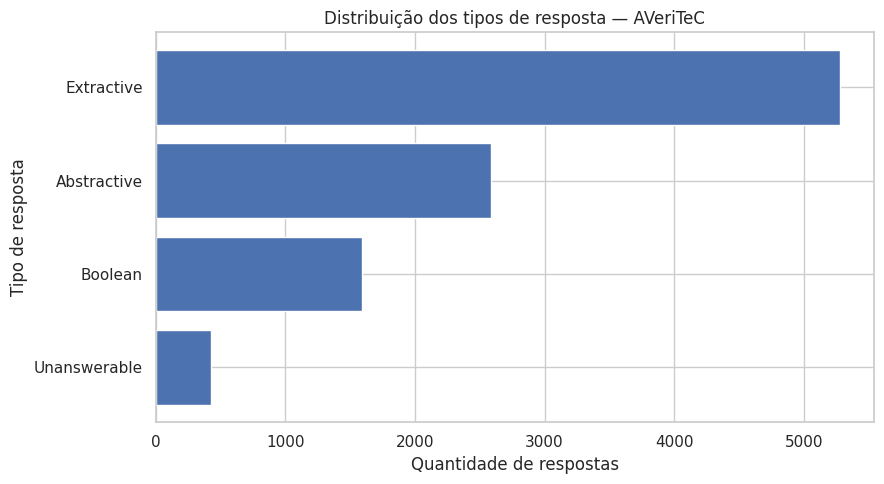

In [34]:
# Distribuição dos tipos de resposta

tipos_grafico = (
    tipos_resposta_df["Tipo"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

plt.barh(
    tipos_grafico.index,
    tipos_grafico.values
)

plt.title("Distribuição dos tipos de resposta — AVeriTeC")
plt.xlabel("Quantidade de respostas")
plt.ylabel("Tipo de resposta")

plt.tight_layout()
plt.show()

#### Interpretação dos tipos de resposta

Foram identificadas **9.878 respostas** associadas às perguntas de verificação presentes nas partições de treino e desenvolvimento.

O tipo mais frequente é `Extractive`, com **5.278 respostas (53,43%)**, indicando que mais da metade das respostas utiliza conteúdo extraído diretamente das fontes de evidência.

As respostas `Abstractive` representam **2.586 ocorrências (26,18%)**, enquanto respostas do tipo `Boolean` correspondem a **1.589 registros (16,09%)**. O tipo `Unanswerable` é o menos frequente, com **425 respostas (4,30%)**.

A presença de diferentes tipos de resposta mostra que a estrutura de evidências do AVeriTeC não se limita a um único formato. As informações utilizadas na verificação podem envolver trechos extraídos das fontes, respostas sintetizadas, respostas booleanas ou situações em que não foi possível obter uma resposta para a pergunta formulada.

Essa diversidade é relevante para etapas posteriores do projeto, pois indica que o processamento das evidências deve considerar diferentes formas de representação e diferentes níveis de disponibilidade da informação.

## 9. Síntese da Análise Exploratória

A análise exploratória do AVeriTeC permitiu caracterizar a estrutura do conjunto, avaliar a qualidade dos dados e identificar padrões relacionados às classes, ao conteúdo textual e às evidências utilizadas no processo de verificação.

As principais descobertas são sintetizadas a seguir, juntamente com limitações identificadas e implicações para as próximas etapas do projeto.

### 9.1 Estrutura e qualidade dos dados

As partições analisadas contêm **3.568 registros**, sendo **3.068 no conjunto de treino** e **500 no conjunto de desenvolvimento**, com **14 variáveis** em ambas.

Os campos centrais para a tarefa de verificação apresentam elevada completude. `label`, `justification`, `required_reannotation`, `fact_checking_article`, `claim_types`, `fact_checking_strategies` e `questions` não apresentaram valores ausentes.

Foi identificado apenas **um registro sem conteúdo em `claim` (0,03%)** no conjunto de treino. Como esse registro mantém rótulo, justificativa, metadados e evidências, optou-se por preservá-lo para análises que não dependem diretamente do texto da alegação.

As maiores proporções de ausência concentram-se em metadados e URLs, especialmente `cached_original_claim_url`, `original_claim_url`, `speaker`, `reporting_source` e `location_ISO_code`.

Não foram identificados registros completamente duplicados nas partições de treino ou desenvolvimento. Entretanto, foram observadas alegações textualmente repetidas. No conjunto de treino, **109 registros (3,55%)** estão envolvidos em repetições, correspondendo a **40 alegações distintas** que aparecem mais de uma vez. No desenvolvimento, foram identificados **15 registros (3,00%)**, correspondendo a **6 alegações distintas repetidas**.

Também foram identificadas **4 alegações textualmente idênticas presentes simultaneamente nos conjuntos de treino e desenvolvimento**, correspondendo a **0,81% das alegações distintas do conjunto de desenvolvimento**. Essa sobreposição deverá ser considerada em futuras etapas de preparação e avaliação dos dados, especialmente em abordagens baseadas no texto das alegações.

Dessa forma, os dados essenciais para classificação e análise das evidências apresentam boa completude, enquanto informações complementares possuem disponibilidade mais variável.

### 9.2 Distribuição das classes

A distribuição dos rótulos apresenta **desbalanceamento entre as classes**.

No conjunto de treino, `Refuted` representa **56,78%** dos registros e `Supported` **27,67%**, enquanto `Not Enough Evidence` corresponde a **9,19%** e `Conflicting Evidence/Cherrypicking` a **6,36%**.

O conjunto de desenvolvimento apresenta comportamento semelhante, com predominância de `Refuted` (**61,00%**) e menor representação das demais classes.

Esse padrão deverá ser considerado em etapas posteriores de modelagem e avaliação, uma vez que métricas agregadas podem ocultar diferenças de desempenho entre classes mais e menos representadas.

### 9.3 Características textuais das alegações

Após a exclusão do único registro sem conteúdo textual, foram analisadas **3.067 claims válidas no treino** e **500 no desenvolvimento**.

As alegações são relativamente curtas. No treino, apresentam média de **17,04 palavras** e mediana de **15 palavras**. No desenvolvimento, a média é de **17,39 palavras** e a mediana de **16 palavras**.

Pelo critério do intervalo interquartil (IQR), foram identificadas **96 alegações com mais de 36 palavras**, correspondendo a **3,13%** das claims válidas do treino.

A inspeção dos registros mais extensos mostrou principalmente citações, declarações compostas e alegações com maior quantidade de contexto, sem evidências claras de erros estruturais. Por esse motivo, esses registros foram mantidos.

### 9.4 Padrões lexicais

A análise lexical mostrou recorrência de termos associados principalmente a **política, saúde pública, localidades e questões quantitativas**.

Entre as palavras mais frequentes aparecem termos relacionados à pandemia e à saúde, como `covid`, `coronavirus`, `pandemic` e `health`, além de referências políticas como `president`, `trump`, `donald` e `biden`.

A análise de bigramas forneceu maior contexto a esses resultados. Expressões como `donald trump`, `south africa`, `united states`, `joe biden`, `covid pandemic`, `novel coronavirus`, `prime minister` e `barack obama` estão entre as combinações recorrentes.

Os resultados indicam que o corpus contém forte presença de alegações relacionadas a acontecimentos políticos, questões de saúde pública, figuras públicas e diferentes contextos geográficos.

### 9.5 Entidades nomeadas e limitações do NER

A exploração por reconhecimento de entidades nomeadas identificou **7.979 ocorrências de entidades**, correspondentes a **3.243 formas distintas**.

As categorias mais frequentes foram entidades geopolíticas (`GPE`), pessoas (`PERSON`) e organizações (`ORG`), além de datas, valores numéricos, grupos nacionais ou políticos, porcentagens e valores monetários.

Entretanto, a inspeção dos resultados revelou erros e inconsistências na classificação automática, incluindo organizações classificadas como localidades e termos semelhantes classificados em categorias diferentes.

Por esse motivo, o NER foi utilizado apenas como ferramenta exploratória. Suas contagens não devem ser interpretadas como uma anotação validada das entidades presentes no conjunto.

### 9.6 Estrutura das evidências

Todos os registros analisados possuem pelo menos **uma pergunta e uma resposta** associadas à estrutura de evidências.

No conjunto de treino, cada alegação apresenta em média **2,60 perguntas e 2,76 respostas**. No desenvolvimento, as médias são de **2,57 perguntas e 2,80 respostas**.

Foram identificadas **9.878 respostas** no total. O tipo `Extractive` é predominante, representando **53,43%** das respostas, seguido por `Abstractive` (**26,18%**), `Boolean` (**16,09%**) e `Unanswerable` (**4,30%**).

Esses resultados mostram que a verificação das alegações pode envolver múltiplas perguntas e evidências e que essas evidências são representadas em diferentes formatos.

### 9.7 Principais desafios e oportunidades para o projeto

A análise exploratória permite destacar alguns aspectos relevantes para as próximas etapas do projeto FOMO.

O **desbalanceamento das classes** deverá ser considerado na definição das estratégias de avaliação, especialmente para evitar que o desempenho nas classes predominantes oculte dificuldades nas categorias menos representadas.

A presença de **múltiplas perguntas e respostas por alegação** mostra que a verificação não depende necessariamente de uma única evidência. Isso representa uma oportunidade para considerar conjuntamente alegação, contexto e evidências durante o desenvolvimento da solução.

A diversidade dos tipos de resposta também indica que o processamento deverá lidar com diferentes formas de representação da evidência, incluindo trechos extraídos, respostas sintetizadas, respostas booleanas e casos em que não existe uma resposta disponível.

As ausências encontradas estão concentradas principalmente em metadados e URLs. Portanto, etapas posteriores que utilizem informações como autor, localização ou fonte deverão considerar que esses campos não estão disponíveis para todos os registros.

A presença de alegações textualmente repetidas e a identificação de **4 alegações idênticas entre treino e desenvolvimento** também deverão ser consideradas em futuras estratégias de separação e avaliação dos dados, especialmente em abordagens sensíveis à similaridade textual.

Por fim, os resultados do reconhecimento automático de entidades demonstram que técnicas de processamento de linguagem natural podem auxiliar na exploração do corpus, mas seus resultados precisam ser interpretados com cautela devido à possibilidade de erros de classificação.

### 9.8 Conclusão da EDA

De forma geral, o AVeriTeC apresenta uma estrutura rica para tarefas de verificação de alegações, combinando texto, classificação, metadados e evidências estruturadas.

A análise identificou boa completude dos campos centrais, desbalanceamento entre os rótulos, diversidade temática nas alegações e presença sistemática de perguntas e respostas de evidência.

Também foram identificados aspectos que exigem atenção nas próximas etapas, como a ausência parcial de alguns metadados, a menor representação de determinadas classes, a presença de alegações textualmente repetidas e de uma pequena sobreposição entre treino e desenvolvimento, além das limitações de técnicas automáticas de processamento textual.

Esses resultados fornecem uma base para as próximas decisões relacionadas à organização dos dados, definição do esquema, seleção das informações relevantes e posterior preparação dos conjuntos utilizados no projeto.